# 02 · Microstructure layer: volatility, volume curve, liquidity, regimes

Reads every cleaned day produced by `01_data_cleaning.ipynb` and builds the **inputs** of the impact model, the optimizer and the benchmarks.
**Edit only the CONFIG cell, then Run All.**

| Section | Output (in `OUT_DIR`) | Used by |
|---|---|---|
| 1 · Inventory | `inventory.csv` | sanity check |
| 2 · Walk-forward split | `split.json` | every later stage (no leakage) |
| 3 · Hourly profile | `hourly_profile.parquet`, `minutes_all.parquet` | regimes, impact model |
| 4 · Volatility sampling (signature plot) | `signature.csv` | choice of return frequency |
| 5 · Intraday volume curve forecasts | `volume_curve_forecasts.parquet` | VWAP, POV benchmarks |
| 6 · Volatility & liquidity by hour of day | `hod_forecasts.parquet` | optimizer (σ, depth per hour) |
| 7 · Regimes | `regimes.parquet` | regime analysis |
| 8 · Execution universe | `order_grid.csv`, `executions.parquet` | simulator / backtest |

**Rule used everywhere:** anything that is *estimated* (curves, σ, thresholds, sizes) uses only days **before** the day it is applied to.

In [1]:
# ============================== CONFIG — edit this cell only ==============================
import os
# Folder that contains the day folders (7th sept, 8th sept, ...). Any parent folder works: it is searched recursively.
ROOT    = r"C:\Users\Nitish Singh\OneDrive\Desktop\ope_daywise"
SYMBOL  = "ETHUSDT"
OUT_DIR = os.path.join(ROOT, "analysis", SYMBOL)

MIN_CALIB_DAYS = 4                 # walk-forward: a day is a test day once this many earlier days exist
SLOT_MIN       = 5                 # resolution of the intraday volume curve (minutes)
SIGNATURE_S    = (0.1, 1, 5, 10, 30, 60, 300)   # sampling intervals for the volatility signature plot
NOISE_TOL      = 0.10              # pick the finest sampling whose variance is within 10% of the 60 s value
SIZE_MULTS     = (0.25, 1, 3, 10)  # order size as a multiple of median bid depth within 10 bps
HORIZONS_MIN   = (5, 15, 30, 60, 120)
START_STEP_MIN = 15                # candidate start times on test days
MIN_WINDOW_USABLE = 0.95           # keep a window only if >= 95% of its minutes have a valid book
MIN_MINUTES_LAMBDA = 30            # minimum usable minutes in an hour to estimate Kyle's lambda
MAX_PARTICIPATION  = 0.30          # size/horizon cells above 30% of expected market volume are not executed
# =========================================================================================

In [2]:
import glob, json, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
out = Path(OUT_DIR); out.mkdir(parents=True, exist_ok=True)
C, G, D = "#2f6fdf", "#b5bcc5", "#1b3f8f"     # one series colour, context grey, emphasis
def style(ax, title):
    ax.set_title(title, loc="left", fontsize=11)
    ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="y", color="#e6e8eb", lw=0.8)

# ---- find every cleaned day ----
found = {}
for qs in sorted(glob.glob(os.path.join(ROOT, "**", "clean", SYMBOL, "*", "qc_summary.json"), recursive=True)):
    d = os.path.basename(os.path.dirname(qs))
    if d in found: print("duplicate day folder ignored:", os.path.dirname(qs)); continue
    found[d] = os.path.dirname(qs)
assert found, f"no cleaned days found under {ROOT}"
DATES = sorted(found)
print(f"{len(DATES)} days found:", ", ".join(DATES))

8 days found: 2026-09-07, 2026-09-08, 2026-09-09, 2026-09-10, 2026-09-11, 2026-09-12, 2026-09-13, 2026-09-14


## 1 · Inventory

In [3]:
M_COLS = ["time", "mid", "mid_open", "spread_bps", "imb_l1", "ofi_l1", "buy_qty", "sell_qty", "volume", "signed_qty",
          "notional", "vwap", "n_trades", "n_taker_orders", "rv", "usable", "usable_share",
          "bid_depth_10bps", "ask_depth_10bps", "bid_depth_25bps", "ask_depth_25bps"]
inv_rows, mins, qcs = [], [], []
for d in DATES:
    f = found[d]
    s = json.load(open(os.path.join(f, "qc_summary.json")))
    q = pd.read_csv(os.path.join(f, "qc_hourly.csv")); q["date"] = d; qcs.append(q)
    m = pd.read_parquet(os.path.join(f, "panel_1min.parquet"), columns=M_COLS); m["date"] = d; mins.append(m)
    inv_rows.append({
        "date": d, "weekday": pd.Timestamp(d).day_name()[:3],
        "hours_ok": int(q.hour_ok.sum()),
        "usable_minutes_%": round(100 * m.usable.mean(), 1),
        "book_init": ", ".join(f"{k}:{v}" for k, v in q.book_init.value_counts().items()),
        "volume_ETH": round(s["trades"]["volume"]), "notional_$M": round(s["trades"]["notional"] / 1e6),
        "trades": s["trades"]["rows_clean"], "taker_orders": s["taker_orders"]["n"],
        "price_open": round(m.mid.dropna().iloc[0], 2) if m.mid.notna().any() else np.nan,
        "price_close": round(m.mid.dropna().iloc[-1], 2) if m.mid.notna().any() else np.nan,
    })
inventory = pd.DataFrame(inv_rows).set_index("date")
QC = pd.concat(qcs, ignore_index=True)
M = pd.concat(mins, ignore_index=True); del mins
inventory.to_csv(out / "inventory.csv")
inventory

,weekday,hours_ok,usable_minutes_%,book_init,volume_ETH,notional_$M,trades,taker_orders,price_open,price_close
date,,,,,,,,,,
2026-09-07,Mon,23,95.8,"snapshot:15, carried_from_previous_hour:9",2590927,6461,3599862,568213,2509.15,2488.92
2026-09-08,Tue,24,98.3,"carried_from_previous_hour:22, rebuilt_from_em...",3358052,8326,4254574,654943,2489.50,2483.88
2026-09-09,Wed,24,99.0,"carried_from_previous_hour:22, rebuilt_from_em...",3602506,8975,4687541,727827,2484.92,2466.96
2026-09-10,Thu,23,95.1,"carried_from_previous_hour:22, rebuilt_from_em...",3555881,8704,4552897,777812,2467.66,2437.04
2026-09-11,Fri,21,86.7,"carried_from_previous_hour:23, rebuilt_from_em...",6368406,16145,7910411,1355053,2439.45,2515.46
2026-09-12,Sat,24,99.2,"carried_from_previous_hour:23, rebuilt_from_em...",1391771,3515,1713727,356843,2514.28,2524.77
2026-09-13,Sun,23,95.0,"carried_from_previous_hour:23, rebuilt_from_em...",2337613,5824,2734970,511120,2524.40,2475.48
2026-09-14,Mon,22,90.8,"carried_from_previous_hour:15, snapshot:8, reb...",4558630,11515,5801859,909216,2475.00,2514.46


## 2 · Walk-forward split (fixed before looking at any result)
To evaluate on day *d*, everything is estimated from the days **before** *d* only. The first `MIN_CALIB_DAYS` days are calibration-only.

In [4]:
TEST_DATES = DATES[MIN_CALIB_DAYS:]
CALIB0 = DATES[:MIN_CALIB_DAYS]                      # initial block: used for fixed thresholds (regimes, sizes)
SPLIT = {d: [x for x in DATES if x < d] for d in TEST_DATES}
json.dump({"calibration_block": CALIB0, "walk_forward": SPLIT}, open(out / "split.json", "w"), indent=1)
pd.DataFrame([{"test_day": d, "weekday": pd.Timestamp(d).day_name(), "calibrated_on": f"{v[0]} … {v[-1]} ({len(v)} days)"}
              for d, v in SPLIT.items()])

,test_day,weekday,calibrated_on
0,2026-09-11,Friday,2026-09-07 … 2026-09-10 (4 days)
1,2026-09-12,Saturday,2026-09-07 … 2026-09-11 (5 days)
2,2026-09-13,Sunday,2026-09-07 … 2026-09-12 (6 days)
3,2026-09-14,Monday,2026-09-07 … 2026-09-13 (7 days)


## 3 · Minute panel and hourly profile
1-minute returns use the **last** mid of consecutive minutes and are kept only when both minutes are usable.
Kyle's λ per hour: OLS of the 1-minute mid return (bps) on signed traded notional ($M) — a first, model-free look at price impact per unit of order flow.

In [5]:
M["ts"] = pd.to_datetime(M.time, unit="ms", utc=True)
M["date"] = M["date"].astype(str)
M["hour"] = ((M.time - 1) // 3_600_000 % 24).astype(int)          # bar end-labelled: 00:01 .. 01:00 belongs to hour 0
M["minute_of_day"] = ((M.time - 1) // 60_000 % 1440).astype(int)
M["slot"] = M.minute_of_day // SLOT_MIN
M["weekend"] = pd.to_datetime(M.date).dt.dayofweek >= 5
M["usable"] = M.usable.astype(bool)
M = M.sort_values("time").reset_index(drop=True)
prev_mid = M.mid.shift(1); prev_ok = M.usable.shift(1, fill_value=False) & ((M.time - M.time.shift(1)) == 60_000)
M["r1m_bps"] = np.where(M.usable & prev_ok, np.log(M.mid / prev_mid) * 1e4, np.nan)
M["depth10"] = 0.5 * (M.bid_depth_10bps + M.ask_depth_10bps)
M["depth25"] = 0.5 * (M.bid_depth_25bps + M.ask_depth_25bps)
M["signed_notional_M"] = M.signed_qty * M.vwap.fillna(M.mid) / 1e6
M.loc[~M.usable, ["depth10", "depth25", "spread_bps", "imb_l1"]] = np.nan

def kyle_lambda(g):
    g = g.dropna(subset=["r1m_bps", "signed_notional_M"])
    if len(g) < MIN_MINUTES_LAMBDA or g.signed_notional_M.var() == 0: return np.nan
    x = g.signed_notional_M.values; y = g.r1m_bps.values
    return float(np.cov(x, y, ddof=1)[0, 1] / np.var(x, ddof=1))

grp = M.groupby(["date", "hour"])
H = pd.DataFrame({
    "volume": grp.volume.sum(), "notional_M": grp.notional.sum() / 1e6, "trades": grp.n_trades.sum(),
    "buy_share": grp.buy_qty.sum() / grp.volume.sum(),
    "usable_share": grp.usable.mean(),
    "spread_bps": grp.spread_bps.mean(), "depth10": grp.depth10.mean(), "depth25": grp.depth25.mean(),
    "sigma_1m_bps": grp.r1m_bps.std(),                       # std of 1-minute returns
    "n_ret": grp.r1m_bps.count(),
    "kyle_lambda_bps_per_M": grp.apply(kyle_lambda, include_groups=False),
    "amihud_bps_per_M": grp.apply(lambda g: (g.r1m_bps.abs() / (g.notional / 1e6)).replace(np.inf, np.nan).mean(), include_groups=False),
}).reset_index()
H["sigma_1h_bps"] = H.sigma_1m_bps * np.sqrt(60)
H = H.merge(QC[["date", "hour", "hour_ok"]], on=["date", "hour"], how="left")
H["hour_ok"] = H.hour_ok.fillna(False).astype(bool)
H["weekday"] = pd.to_datetime(H.date).dt.day_name().str[:3]
H.to_parquet(out / "hourly_profile.parquet", index=False)
M.to_parquet(out / "minutes_all.parquet", index=False)
print(f"{len(H)} date-hours, {int(H.hour_ok.sum())} usable")
H[H.hour_ok].describe(percentiles=[.1, .5, .9]).T[["mean", "10%", "50%", "90%"]].round(3)

192 date-hours, 184 usable


,mean,10%,50%,90%
hour,11.391,2.000,11.000,21.000
volume,124864.676,40120.953,96512.861,233580.628
notional_M,311.909,100.672,241.048,579.780
trades,163441.332,58696.900,130152.000,279477.100
buy_share,0.499,0.430,0.498,0.575
usable_share,0.991,1.000,1.000,1.000
spread_bps,0.040,0.040,0.040,0.041
depth10,3142.399,2566.507,3129.738,3699.087
depth25,10388.783,8553.445,10288.955,12161.892
sigma_1m_bps,5.135,2.753,4.610,7.994


## 4 · Which return frequency? (volatility signature plot)
Realized variance computed at a too-fine sampling interval is inflated by microstructure noise (quote flicker, bounce).
We compute the average realized variance per hour for each sampling interval and use the finest interval (≥ 1 s) whose
variance is within `NOISE_TOL` of the 60-second value.

In [6]:
def rv_per_hour(t_ms, mid, ok, step_ms):
    # mean realized variance per usable hour (bps^2) at a given sampling step
    if len(t_ms) == 0: return np.nan, 0
    t0 = t_ms[0]; keep = ((t_ms - t0) % step_ms) == 0
    t, x, o = t_ms[keep], np.log(mid[keep]), ok[keep]
    good = o[1:] & o[:-1] & (np.diff(t) == step_ms)
    r = np.diff(x)[good] * 1e4
    hours = good.sum() * step_ms / 3_600_000
    return (np.sum(r ** 2) / hours if hours > 0 else np.nan), hours

sig = []
for d in DATES:
    f = found[d]
    p1 = pd.read_parquet(os.path.join(f, "panel_1s.parquet"), columns=["time", "mid", "usable"])
    t1, x1, o1 = p1.time.values, p1.mid.values, p1.usable.values.astype(bool) & np.isfinite(p1.mid.values)
    for s_ in SIGNATURE_S:
        if s_ < 1:
            p = pd.read_parquet(os.path.join(f, "panel_100ms.parquet"), columns=["time", "bid_px", "ask_px", "usable"])
            mid = 0.5 * (p.bid_px.values + p.ask_px.values)
            v, hrs = rv_per_hour(p.time.values, mid, p.usable.values.astype(bool) & np.isfinite(mid), int(s_ * 1000)); del p
        else:
            v, hrs = rv_per_hour(t1, x1, o1, int(s_ * 1000))
        sig.append({"date": d, "sampling_s": s_, "rv_per_hour_bps2": v, "hours": hrs})
SIG = pd.DataFrame(sig)
sig_mean = SIG.groupby("sampling_s").apply(lambda g: np.average(g.rv_per_hour_bps2, weights=g.hours), include_groups=False)
ratio = sig_mean / sig_mean.loc[60]
# candidates start at 1 s (the 1-second panel is what the later stages use); 100 ms is shown only as a noise diagnostic
RV_SAMPLING_S = float(min([s_ for s_ in SIGNATURE_S if 1 <= s_ <= 60 and abs(ratio.loc[s_] - 1) <= NOISE_TOL] or [60]))
SIG.to_csv(out / "signature.csv", index=False)
print("hourly vol (bps) by sampling interval:", (np.sqrt(sig_mean)).round(1).to_dict())
print(f"variance ratio vs 60s:", ratio.round(3).to_dict(), f"\n-> realized volatility is computed from {RV_SAMPLING_S:g}-second returns")

hourly vol (bps) by sampling interval: {0.1: 35.8, 1.0: 41.2, 5.0: 43.5, 10.0: 44.2, 30.0: 44.3, 60.0: 44.4, 300.0: 46.8}
variance ratio vs 60s: {0.1: 0.653, 1.0: 0.864, 5.0: 0.96, 10.0: 0.994, 30.0: 1.0, 60.0: 1.0, 300.0: 1.113} 
-> realized volatility is computed from 5-second returns


## 5 · Intraday volume curve — forecast for each test day
For each test day the curve is the average **share of daily volume** per `SLOT_MIN`-minute slot over its calibration days.
It is scored against the realized curve of the test day by the share of volume that would be placed in the wrong slot
(total variation distance, 0 = perfect), and compared with a flat curve (= TWAP).

In [7]:
slot_vol = M.groupby(["date", "slot"]).volume.sum().unstack(fill_value=0.0)
share = slot_vol.div(slot_vol.sum(axis=1), axis=0)                     # each row sums to 1
n_slots = share.shape[1]
daily_vol = slot_vol.sum(axis=1)

def smooth_circular(v, k=3):
    # k-slot moving average that wraps around midnight
    pad = np.r_[v[-k:], v, v[:k]]
    return np.convolve(pad, np.ones(2 * k + 1) / (2 * k + 1), mode="same")[k:-k]

rows, score = [], []
for d, cal in SPLIT.items():
    f = smooth_circular(share.loc[cal].mean().values); f = f / f.sum()
    for i, v in enumerate(f):
        rows.append({"test_date": d, "slot": i, "start_min": i * SLOT_MIN, "share_forecast": v})
    real = share.loc[d].values
    score.append({"test_day": d,
                  "misallocated_forecast_%": 100 * 0.5 * np.abs(f - real).sum(),
                  "misallocated_flat_%": 100 * 0.5 * np.abs(1 / n_slots - real).sum(),
                  "daily_volume_forecast_ETH": daily_vol.loc[cal].mean(), "daily_volume_actual_ETH": daily_vol.loc[d]})
VC = pd.DataFrame(rows); VC.to_parquet(out / "volume_curve_forecasts.parquet", index=False)
SC = pd.DataFrame(score).set_index("test_day")
SC["improvement_vs_flat_%"] = 100 * (1 - SC["misallocated_forecast_%"] / SC["misallocated_flat_%"])
SC.round(1)

,misallocated_forecast_%,misallocated_flat_%,daily_volume_forecast_ETH,daily_volume_actual_ETH,improvement_vs_flat_%
test_day,,,,,
2026-09-11,40.6,50.7,3276841.4,6368405.8,19.9
2026-09-12,30.9,26.6,3895154.3,1391771.0,-16.1
2026-09-13,39.3,39.9,3477923.7,2337613.0,1.6
2026-09-14,34.2,34.1,3315022.2,4558630.2,-0.2


## 6 · Volatility and liquidity by hour of day (forecasts for the optimizer)
For each test day: per hour of day, the volatility of `RV_SAMPLING_S` returns scaled to 1 minute, the median bid depth within 10/25 bps,
the median spread, the mean traded volume and the median Kyle λ, all from its calibration days only.

In [8]:
# realized volatility per (date, hour) at the chosen sampling, from the 1s panel
step = int(RV_SAMPLING_S * 1000)
rv_rows = []
for d in DATES:
    p1 = pd.read_parquet(os.path.join(found[d], "panel_1s.parquet"), columns=["time", "mid", "usable"])
    t, x, o = p1.time.values, p1.mid.values, p1.usable.values.astype(bool) & np.isfinite(p1.mid.values)
    keep = ((t - t[0]) % step) == 0
    t, x, o = t[keep], np.log(x[keep]), o[keep]
    good = o[1:] & o[:-1] & (np.diff(t) == step)
    r = np.where(good, np.diff(x) * 1e4, np.nan)
    hr = ((t[1:] - 1) // 3_600_000) % 24
    df = pd.DataFrame({"hour": hr, "r2": r ** 2, "ok": good}).groupby("hour").agg(rv=("r2", "sum"), n=("ok", "sum"))
    df["date"] = d; rv_rows.append(df.reset_index())
RVH = pd.concat(rv_rows)
RVH["sigma_1m_rv_bps"] = np.sqrt(RVH.rv / RVH.n.replace(0, np.nan) * (60_000 / step))   # per-minute vol from fine returns
H = H.drop(columns=[c for c in ["sigma_1m_rv_bps"] if c in H]).merge(RVH[["date", "hour", "sigma_1m_rv_bps"]], on=["date", "hour"], how="left")
H.loc[H.usable_share < 0.5, "sigma_1m_rv_bps"] = np.nan
H.to_parquet(out / "hourly_profile.parquet", index=False)

fc = []
for d, cal in SPLIT.items():
    h = H[H.date.isin(cal) & H.hour_ok].groupby("hour")
    f = pd.DataFrame({"sigma_1m_bps": np.sqrt(h.sigma_1m_rv_bps.apply(lambda s: np.nanmean(s ** 2))),
                      "depth10_median": h.depth10.median(), "depth25_median": h.depth25.median(),
                      "spread_bps_median": h.spread_bps.median(), "volume_mean": h.volume.mean(),
                      "kyle_lambda_median": h.kyle_lambda_bps_per_M.median()}).reindex(range(24))
    f = f.interpolate(limit_direction="both")            # hours with no usable calibration data borrow neighbours
    f["test_date"] = d; fc.append(f.reset_index().rename(columns={"index": "hour"}))
HOD = pd.concat(fc, ignore_index=True); HOD.to_parquet(out / "hod_forecasts.parquet", index=False)

# how well does the hour-of-day forecast predict realized volatility? (correlation over test hours)
chk = H[H.date.isin(TEST_DATES) & H.hour_ok].merge(HOD, left_on=["date", "hour"], right_on=["test_date", "hour"], suffixes=("", "_fc"))
print(f"test hours: {len(chk)} | corr(forecast σ, realized σ) = {chk.sigma_1m_bps_fc.corr(chk.sigma_1m_rv_bps):.2f}"
      f" | corr(forecast depth10, realized depth10) = {chk.depth10_median.corr(chk.depth10):.2f}")
HOD[HOD.test_date == TEST_DATES[-1]].round(3)

test hours: 90 | corr(forecast σ, realized σ) = 0.16 | corr(forecast depth10, realized depth10) = -0.09


,hour,sigma_1m_bps,depth10_median,depth25_median,spread_bps_median,volume_mean,kyle_lambda_median,test_date
72,0,4.760,3272.943,11005.280,0.040,83538.662,1.821,2026-09-14
73,1,5.170,2989.410,10517.563,0.040,81159.872,1.763,2026-09-14
74,2,4.627,3092.540,10852.111,0.040,84260.251,1.542,2026-09-14
75,3,4.156,2943.297,10234.357,0.040,79952.718,1.145,2026-09-14
76,4,4.215,3102.552,10656.874,0.040,84697.288,1.448,2026-09-14
77,5,4.262,3044.272,10066.328,0.040,84055.244,1.408,2026-09-14
78,6,3.914,3168.206,11176.270,0.040,86385.463,0.950,2026-09-14
79,7,4.403,3264.360,9997.702,0.040,112865.026,1.268,2026-09-14
80,8,5.171,3010.214,9771.254,0.040,124468.880,1.216,2026-09-14
81,9,4.256,3384.600,11178.411,0.040,119241.775,1.068,2026-09-14


## 7 · Regimes
Each hour is labelled by volatility (low / normal / high) and liquidity (thin / normal / deep, from bid+ask depth within 10 bps).
Tercile thresholds come from the **initial calibration block only** and stay fixed, so test days never influence them.
A strategy can only know the regime of hours that have finished, so `*_prev` columns (previous hour) are what a trader would see at decision time.

In [9]:
base = H[H.date.isin(CALIB0) & H.hour_ok]
v_lo, v_hi = base.sigma_1m_rv_bps.quantile([1 / 3, 2 / 3])
l_lo, l_hi = base.depth10.quantile([1 / 3, 2 / 3])
R = H[["date", "hour", "weekday", "hour_ok", "sigma_1m_rv_bps", "depth10", "volume", "kyle_lambda_bps_per_M"]].copy()
R["vol_regime"] = pd.cut(R.sigma_1m_rv_bps, [-np.inf, v_lo, v_hi, np.inf], labels=["low", "normal", "high"])
R["liq_regime"] = pd.cut(R.depth10, [-np.inf, l_lo, l_hi, np.inf], labels=["thin", "normal", "deep"])
R = R.sort_values(["date", "hour"]).reset_index(drop=True)
R["vol_regime_prev"] = R.vol_regime.shift(1); R["liq_regime_prev"] = R.liq_regime.shift(1)
R.loc[~R.hour_ok, ["vol_regime", "liq_regime"]] = np.nan
R.to_parquet(out / "regimes.parquet", index=False)
print(f"thresholds (from {CALIB0[0]}…{CALIB0[-1]}): σ_1m {v_lo:.2f} / {v_hi:.2f} bps | depth10 {l_lo:,.0f} / {l_hi:,.0f} ETH")
print("\nusable hours by regime (all days):")
pd.crosstab(R.vol_regime, R.liq_regime, margins=True)

thresholds (from 2026-09-07…2026-09-10): σ_1m 4.36 / 5.58 bps | depth10 3,231 / 3,471 ETH

usable hours by regime (all days):


liq_regime,thin,normal,deep,All
vol_regime,,,,
low,55,15,12,82
normal,23,10,11,44
high,28,18,12,58
All,106,43,35,184


## 8 · Execution universe: order sizes, horizons and start times
Order sizes are multiples of the median **bid** depth within 10 bps (what a seller consumes), from the calibration block.
Participation = order size ÷ expected market volume over the horizon; cells above `MAX_PARTICIPATION` are left out (not realistic to execute). Start times are every `START_STEP_MIN` minutes on
test days; a window is kept only if at least `MIN_WINDOW_USABLE` of its minutes have a valid book. Every strategy will be run on
exactly these windows (paired comparison).

In [10]:
cb = M[M.date.isin(CALIB0) & M.usable]
D10 = float(np.nanmedian(cb.bid_depth_10bps))
vol_per_min = float(cb.volume.sum() / cb.date.nunique() / 1440)
grid = []
for k in SIZE_MULTS:
    for T in HORIZONS_MIN:
        X = k * D10
        grid.append({"size_mult": k, "X0_ETH": round(X, 3), "X0_$M": round(X * cb.mid.median() / 1e6, 2), "horizon_min": T,
                     "participation_%": round(100 * X / (vol_per_min * T), 2),
                     "in_backtest": X / (vol_per_min * T) <= MAX_PARTICIPATION})
GRID = pd.DataFrame(grid); GRID.to_csv(out / "order_grid.csv", index=False)

ex = []
for d in TEST_DATES:
    md_ = M[M.date == d].set_index("minute_of_day")
    usable = md_.usable.reindex(range(1440), fill_value=False).values.astype(float)
    cs = np.r_[0, np.cumsum(usable)]
    reg = R[R.date == d].set_index("hour")
    for T in HORIZONS_MIN:
        for s0 in range(0, 1440 - T + 1, START_STEP_MIN):
            if (cs[s0 + T] - cs[s0]) / T < MIN_WINDOW_USABLE: continue
            h = s0 // 60
            for k in SIZE_MULTS:
                if k * D10 / (vol_per_min * T) > MAX_PARTICIPATION: continue
                ex.append({"test_date": d, "start_min": s0, "horizon_min": T, "size_mult": k, "X0_ETH": k * D10,
                           "start_time": pd.Timestamp(d, tz="UTC") + pd.Timedelta(minutes=s0),
                           "vol_regime_prev": reg.vol_regime_prev.get(h), "liq_regime_prev": reg.liq_regime_prev.get(h)})
EX = pd.DataFrame(ex); EX.insert(0, "exec_id", np.arange(len(EX)))
EX.to_parquet(out / "executions.parquet", index=False)
print(f"median bid depth within 10 bps (calibration block): {D10:,.0f} ETH | mean market volume: {vol_per_min:,.0f} ETH/min")
print(f"{len(EX):,} execution windows on {len(TEST_DATES)} test days "
      f"({EX.groupby(['test_date','horizon_min','start_min']).ngroups:,} distinct windows; size/horizon cells above {MAX_PARTICIPATION:.0%} participation skipped)")
GRID.pivot(index="size_mult", columns="horizon_min", values="participation_%").rename_axis(
    index="size (x depth10)", columns="horizon (min) → participation %")

median bid depth within 10 bps (calibration block): 3,137 ETH | mean market volume: 2,067 ETH/min
4,668 execution windows on 4 test days (1,695 distinct windows; size/horizon cells above 30% participation skipped)


horizon (min) → participation %,5,15,30,60,120
size (x depth10),,,,,
0.25,7.59,2.53,1.26,0.63,0.32
1.00,30.35,10.12,5.06,2.53,1.26
3.00,91.06,30.35,15.18,7.59,3.79
10.00,303.55,101.18,50.59,25.30,12.65


## 9 · Overview

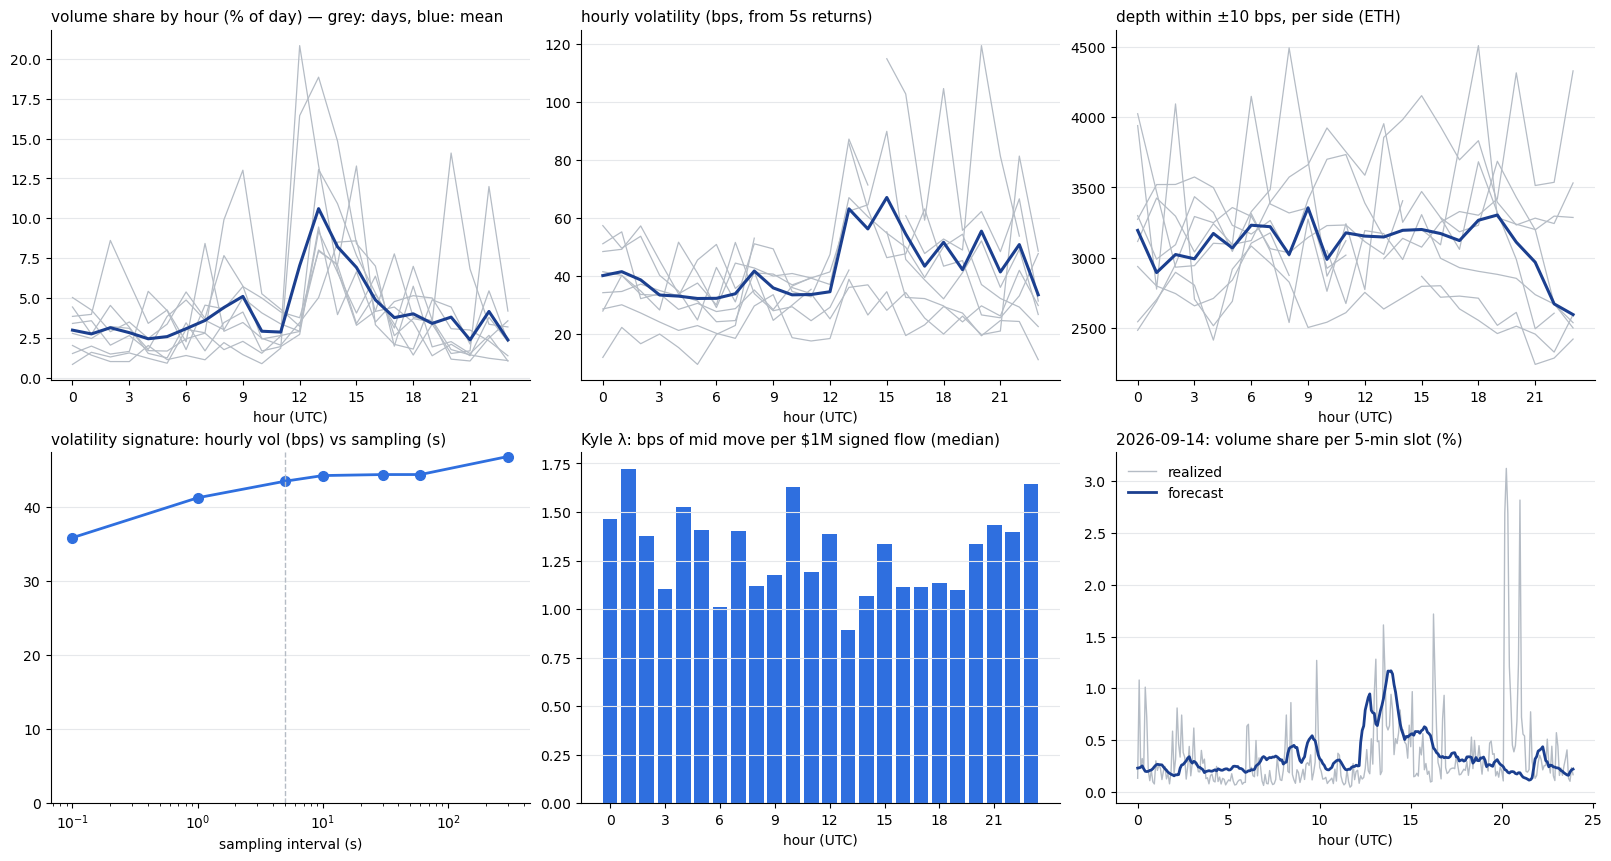

In [11]:
fig, ax = plt.subplots(2, 3, figsize=(16, 8.5), constrained_layout=True)
hours = np.arange(24)

# (a) intraday volume share by hour, each day grey, mean bold
hv = M.groupby(["date", "hour"]).volume.sum().unstack(fill_value=0)
hs = hv.div(hv.sum(axis=1), axis=0) * 100
for d in hs.index: ax[0, 0].plot(hours, hs.loc[d].reindex(hours).values, color=G, lw=0.9)
ax[0, 0].plot(hours, hs.mean().reindex(hours).values, color=D, lw=2.2)
style(ax[0, 0], "volume share by hour (% of day) — grey: days, blue: mean"); ax[0, 0].set_xticks(range(0, 24, 3))

# (b) volatility by hour of day
hh = H[H.hour_ok]
for d in DATES:
    s_ = hh[hh.date == d].set_index("hour").sigma_1m_rv_bps.reindex(hours)
    ax[0, 1].plot(hours, s_.values * np.sqrt(60), color=G, lw=0.9)
ax[0, 1].plot(hours, np.sqrt(hh.groupby("hour").sigma_1m_rv_bps.apply(lambda s: np.nanmean(s ** 2))).reindex(hours).values * np.sqrt(60), color=D, lw=2.2)
style(ax[0, 1], f"hourly volatility (bps, from {RV_SAMPLING_S:g}s returns)"); ax[0, 1].set_xticks(range(0, 24, 3))

# (c) depth within 10 bps by hour of day
for d in DATES:
    s_ = hh[hh.date == d].set_index("hour").depth10.reindex(hours)
    ax[0, 2].plot(hours, s_.values, color=G, lw=0.9)
ax[0, 2].plot(hours, hh.groupby("hour").depth10.median().reindex(hours).values, color=D, lw=2.2)
style(ax[0, 2], "depth within ±10 bps, per side (ETH)"); ax[0, 2].set_xticks(range(0, 24, 3))

# (d) signature plot
ax[1, 0].plot(sig_mean.index, np.sqrt(sig_mean.values), color=C, lw=2, marker="o", ms=7)
ax[1, 0].axvline(RV_SAMPLING_S, color=G, lw=1, ls="--")
ax[1, 0].set_xscale("log"); ax[1, 0].set_ylim(0, None); style(ax[1, 0], "volatility signature: hourly vol (bps) vs sampling (s)")

# (e) Kyle lambda by hour of day (median, calibration+test)
lam = hh.groupby("hour").kyle_lambda_bps_per_M.median().reindex(hours)
ax[1, 1].bar(hours, lam.values, color=C, width=0.8)
style(ax[1, 1], "Kyle λ: bps of mid move per $1M signed flow (median)"); ax[1, 1].set_xticks(range(0, 24, 3))

# (f) volume curve forecast vs realized for the last test day
d = TEST_DATES[-1]
f = VC[VC.test_date == d].share_forecast.values * 100; r_ = share.loc[d].values * 100
x = np.arange(n_slots) * SLOT_MIN / 60
ax[1, 2].plot(x, r_, color=G, lw=1, label="realized"); ax[1, 2].plot(x, f, color=D, lw=2, label="forecast")
ax[1, 2].legend(frameon=False); style(ax[1, 2], f"{d}: volume share per {SLOT_MIN}-min slot (%)")
for a in ax.flat: a.set_xlabel("hour (UTC)" if a not in (ax[1, 0],) else "sampling interval (s)")
fig.savefig(out / "microstructure_overview.png", dpi=120, bbox_inches="tight"); plt.show()

## 10 · Summary

In [12]:
hk = H[H.hour_ok]
summary = {
    "days": DATES, "test_days": TEST_DATES, "usable_hours": int(hk.shape[0]),
    "rv_sampling_s": RV_SAMPLING_S,
    "hourly_vol_bps_median": round(float(np.nanmedian(hk.sigma_1m_rv_bps) * np.sqrt(60)), 1),
    "hourly_vol_bps_p10_p90": [round(float(np.nanpercentile(hk.sigma_1m_rv_bps, q) * np.sqrt(60)), 1) for q in (10, 90)],
    "spread_bps_median": round(float(np.nanmedian(hk.spread_bps)), 4),
    "depth10_ETH_median": round(float(np.nanmedian(hk.depth10))), "depth25_ETH_median": round(float(np.nanmedian(hk.depth25))),
    "kyle_lambda_bps_per_$M_median": round(float(np.nanmedian(hk.kyle_lambda_bps_per_M)), 3),
    "busiest_hours_utc": hs.mean().sort_values(ascending=False).index[:4].tolist(),
    "quietest_hours_utc": hs.mean().sort_values().index[:4].tolist(),
    "volume_curve_improvement_vs_flat_%": round(float(SC["improvement_vs_flat_%"].mean()), 1),
    "D10_ETH": round(D10, 1), "execution_windows": int(len(EX)),
}
json.dump(summary, open(out / "summary.json", "w"), indent=1, default=str)
for k, v in summary.items(): print(f"{k:38s} {v}")

days                                   ['2026-09-07', '2026-09-08', '2026-09-09', '2026-09-10', '2026-09-11', '2026-09-12', '2026-09-13', '2026-09-14']
test_days                              ['2026-09-11', '2026-09-12', '2026-09-13', '2026-09-14']
usable_hours                           184
rv_sampling_s                          5.0
hourly_vol_bps_median                  35.1
hourly_vol_bps_p10_p90                 [22.2, 60.0]
spread_bps_median                      0.0402
depth10_ETH_median                     3130
depth25_ETH_median                     10289
kyle_lambda_bps_per_$M_median          1.269
busiest_hours_utc                      [13, 14, 12, 15]
quietest_hours_utc                     [21, 23, 4, 5]
volume_curve_improvement_vs_flat_%     1.3
D10_ETH                                3136.6
execution_windows                      4668
